In [3]:
import pandas as pd

df = pd.read_csv('wavelet.csv')

In [4]:
X = df.iloc[:, :-1]

Y = df.iloc[:, -1]

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn_classifier = KNeighborsClassifier(n_neighbors = 7 , p = 1 , weights = 'uniform')

In [7]:
knn_classifier.fit(X_train, y_train)


KNeighborsClassifier(n_neighbors=7, p=1)

In [8]:
len(X_val)

933

In [9]:
import time

start = time.time()

y_pred = knn_classifier.predict(X_val)

end = time.time()

print("Time taken to predict the validation set is ", end - start)

Time taken to predict the validation set is  0.8503994941711426


In [10]:
from sklearn import metrics

accuracy = metrics.accuracy_score(y_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.5959271168274384


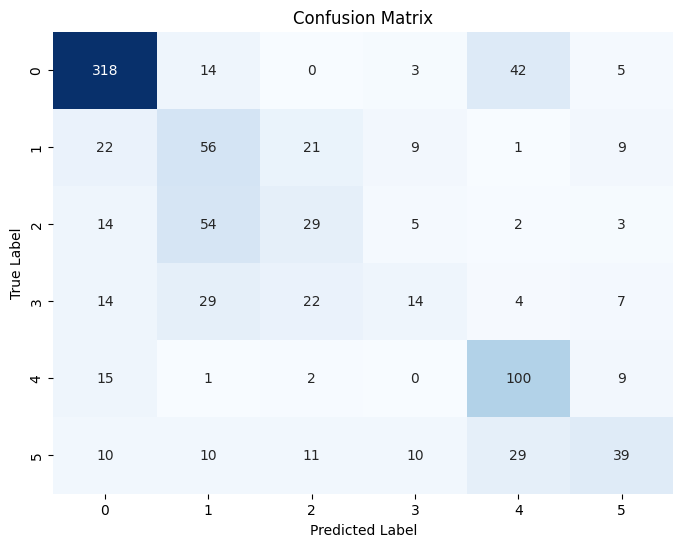

In [11]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [12]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, y_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.5811


In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val, y_pred, average=None)
recall = recall_score(y_val, y_pred, average=None)
f1 = f1_score(y_val, y_pred, average=None)

# Print results for each class
for class_label in range(6):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")



Class 0:
Precision: 0.8092
Recall: 0.8325
F1 Score: 0.8206

Class 1:
Precision: 0.3415
Recall: 0.4746
F1 Score: 0.3972

Class 2:
Precision: 0.3412
Recall: 0.2710
F1 Score: 0.3021

Class 3:
Precision: 0.3415
Recall: 0.1556
F1 Score: 0.2137

Class 4:
Precision: 0.5618
Recall: 0.7874
F1 Score: 0.6557

Class 5:
Precision: 0.5417
Recall: 0.3578
F1 Score: 0.4309



In [14]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4:
		return 0
	elif prediction == 5:
		return 1
	else:
		return 2

In [15]:
y_val

1268    0.0
4082    4.0
1769    0.0
23      0.0
1174    0.0
       ... 
2540    2.0
2955    2.0
4351    5.0
3852    4.0
4600    5.0
Name: 25, Length: 933, dtype: float64

In [16]:
len(y_pred)

933

In [17]:
for i in range (len(y_pred)):
	y_pred[i] = predictionMapping(y_pred[i])

y_val = y_val.apply(predictionMapping)

In [18]:
y_pred

array([0., 0., 0., 1., 0., 1., 0., 2., 0., 0., 0., 2., 2., 1., 0., 0., 2.,
       0., 0., 2., 2., 2., 0., 2., 0., 0., 1., 0., 2., 0., 2., 2., 0., 2.,
       2., 0., 0., 0., 0., 2., 0., 0., 2., 1., 2., 0., 0., 0., 0., 0., 2.,
       0., 0., 2., 0., 0., 2., 0., 0., 1., 2., 2., 0., 2., 2., 2., 0., 0.,
       1., 0., 1., 0., 0., 2., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
       0., 0., 2., 0., 0., 0., 2., 0., 2., 0., 0., 0., 0., 1., 0., 0., 2.,
       0., 0., 1., 0., 0., 2., 0., 0., 0., 0., 2., 0., 0., 2., 2., 1., 0.,
       0., 2., 0., 0., 2., 0., 2., 2., 0., 0., 2., 0., 0., 1., 0., 0., 2.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 2., 0., 0., 2.,
       0., 2., 2., 2., 0., 0., 0., 0., 1., 2., 1., 2., 0., 0., 2., 2., 2.,
       2., 0., 2., 0., 2., 2., 2., 2., 0., 0., 2., 0., 2., 2., 2., 0., 0.,
       2., 0., 0., 1., 0., 2., 0., 0., 2., 2., 0., 2., 0., 2., 2., 0., 2.,
       1., 2., 0., 2., 0., 0., 2., 0., 0., 0., 2., 0., 2., 1., 2., 0., 0.,
       0., 0., 0., 2., 0.

In [19]:
from sklearn import metrics

accuracy = metrics.accuracy_score(y_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.8070739549839229


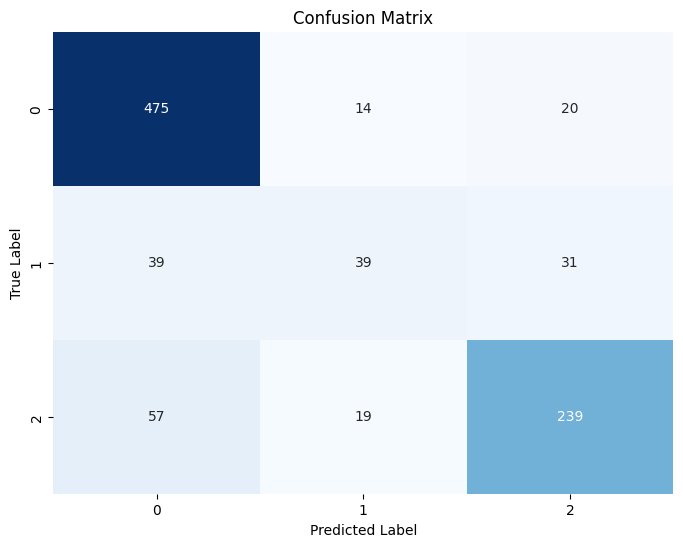

In [20]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [21]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, y_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.7970


In [27]:
y_pred_new = y_pred[y_val != 1]

y_val = y_val[y_val != 1]



IndexError: boolean index did not match indexed array along dimension 0; dimension is 933 but corresponding boolean dimension is 824

In [26]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

ValueError: Found input variables with inconsistent numbers of samples: [824, 933]